For the appendix, I would characterize the data at three levels: **trait coverage and distributions, environmental covariates, and spatial/species coverage**. The notebook already separates these sources in a way that supports this structure: traits come from the Excel tables, environmental layers are cached as cluster-level climate, population/elevation, and soil tables, and species occurrences are linked to the spatial clusters. new_dataset new_dataset new_dataset

I would use **three main appendix figures**, plus a correlation figure if space allows:

1. **Trait data characterization:** missingness plus distributions of the 12 prediction targets in one composite figure.
2. **Environmental feature characterization:** all environmental-feature distributions, grouped by domain, preferably as compact small multiples.
3. **Species spatial distributions:** New Zealand map with selected species as colored occurrence points. I would also provide a small-multiple version because 206 species cannot be distinguished in one overlay.
4. **Optional:** environmental-feature correlation matrix, ordered by domain. This is especially useful because the monthly WorldClim variables are strongly structurally related.

A methodological point from the notebook should be checked before generating final appendix figures. Its generic `load_raster()` function downsamples rasters using `.coarsen(...).sum()`. That is sensible for occurrence/count rasters but changes the scale of continuous variables such as temperature, vapour pressure, solar radiation, elevation, and soil properties. The subsequent climate and soil code averages values over spatial clusters, but it operates on the already coarsened raster. new_dataset For continuous environmental layers I would use `mean()` during coarsening, and reserve `sum()` for occurrence/count rasters. If the cached environmental CSVs were produced with the current `sum()` version, either regenerate them or describe them explicitly as transformed model inputs rather than reporting their values in the original physical units.

## 1. Load the characterization data

The following is a clean appendix-oriented loading block. It uses the cached tables already generated by the notebook, so the figures do not require reopening every raster.

In [ ]:
import sys
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "pdf.fonttype": 42,
})

PROJECT_ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents) if (parent / "loader.py").is_file()),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(f"Could not locate loader.py from {Path.cwd()}")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from loader import PlantDataset

ROOT = PROJECT_ROOT / "data/Ferns"
LAYERS = ROOT / "Complete layers"

In [2]:

# ------------------------------------------------------------------
# Traits
# ------------------------------------------------------------------

trait_minmax = (
    pd.read_excel(ROOT / "FernTraits.xlsx")
    .set_index("Species")
)

species_meta = pd.read_excel(ROOT / "Species list.xlsx")


# ------------------------------------------------------------------
# Environmental covariates already aggregated to spatial clusters
# ------------------------------------------------------------------

clim_df = pd.read_csv(
    LAYERS / "Climatic layers_space_df_v3.csv",
    index_col=0
)

soil_df = pd.read_csv(
    LAYERS / "Soil NZ layers_space_df_v3.csv",
    index_col=0
)

pop_df = pd.read_csv(
    LAYERS / "population density and elevation layer_space_df_v3.csv",
    index_col=0
)


# ------------------------------------------------------------------
# Spatial clusters and species occurrences
# ------------------------------------------------------------------

dataset = PlantDataset(
        ROOT,
        transform=None,
        trait_representation="min_max_range",
        traits_filename="FernTraits.xlsx",
        invalid_bounds_policy='missing',
    )

dataset.get_spatial_graph()

cluster_xy = (
    dataset.space_df
    .groupby("cluster")[["x", "y"]]
    .mean()
    .rename(columns={"x": "lon", "y": "lat"})
)

occurrences = pd.read_csv(ROOT / "index_space_specie.csv")

occurrences = (
    occurrences
    .merge(
        cluster_xy,
        left_on="cluster",
        right_index=True,
        how="left"
    )
)

/home/smonaco/newzeland-plants/.venv/lib/python3.13/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


# 1. Feature and traits distributions

The notebook currently calls `.hist()` independently on climate, population/elevation, and soil data. For the appendix I would replace those exploratory plots with a domain-aware figure. The notebook explicitly constructs climate and soil values at the spatial-cluster level, so the natural observational unit here is the **spatial cluster**, not the species. new_dataset

First construct a long-format table.

In [ ]:
def env_to_long(df, domain):
    x = (
        df
        .rename_axis("cluster")
        .reset_index()
        .melt(
            id_vars="cluster",
            var_name="feature",
            value_name="value",
        )
    )

    x["domain"] = domain
    return x


env_parts = [
    env_to_long(clim_df, "Climate"),
    env_to_long(soil_df, "Soil"),
]

# Split the combined population/elevation table by actual feature name
for feature in pop_df.columns:
    name = feature.lower()

    if "elev" in name:
        domain = "Elevation"
    elif "population" in name or "density" in name:
        domain = "Density"
    else:
        domain = "Other"

    tmp = (
        pop_df[[feature]]
        .rename_axis("cluster")
        .reset_index()
        .melt(
            id_vars="cluster",
            var_name="feature",
            value_name="value",
        )
    )
    tmp["domain"] = domain

    env_parts.append(tmp)

env_long = pd.concat(
    env_parts,
    ignore_index=True,
)

env_long = env_long.replace(
    [np.inf, -np.inf],
    np.nan
).dropna(subset=["value"])


# Canonical feature labels shared with the attribution notebook (analysis_utils.py).
from analysis_utils import env_feature_label as pretty_feature

env_long["feature_label"] = (
    env_long["feature"]
    .map(pretty_feature)
)

## 3a. All features: domain-separated small multiples

For the appendix, I would show **all features**, because selecting only the highly attributed ones makes the data-characterization appendix partly dependent on the model results.

A good compromise is one page per domain. The following function automatically creates a dense small-multiple layout.

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import textwrap

def distribution_ridges(env_long, features, title=None, cmap="viridis", figsize=(7.2, 4.2),
                        showfliers=False, flier_quantiles=(0.01, 0.99), featuredict:dict={},
                        savepath=None, wrap_width=14):
    d = env_long[env_long.feature_label.isin(features)].copy()

    if featuredict:
        assert all(f in featuredict for f in features) and all(f in features for f in featuredict), \
            "All features must be present in the featuredict and vice versa."

    g = d.groupby("feature_label")["value"]
    d["scaled"] = g.transform(
        lambda x: (x - x.median()) / (x.quantile(.75) - x.quantile(.25))
    )
    if not showfliers:
        d = d[
            d.groupby("feature_label")["scaled"].transform(
                lambda x: x.between(x.quantile(flier_quantiles[0]), x.quantile(flier_quantiles[1]))
            )
        ]

    x = np.linspace(
        d.scaled.quantile(.01) - .4,
        d.scaled.quantile(.99) + .4,
        500
    )

    colors = plt.get_cmap(cmap)(np.linspace(.15, .85, len(features)))

    fig, ax = plt.subplots(figsize=figsize)

    for i, (feature, color) in enumerate(zip(features[::-1], colors[::-1])):
        values = d.loc[d.feature_label == feature, "scaled"].dropna()
        density = gaussian_kde(values)(x)
        density = density / density.max() * .75

        ax.fill_between(
            x, i, i + density,
            color=color, alpha=.45
        )
        ax.plot(
            x, i + density,
            color=color, lw=1.3
        )

        ax.scatter(
            values,
            np.full(len(values), i - .06),
            color=color,
            marker="|",
            s=35,
            alpha=.5,
            linewidth=.9
        )

    ax.axvline(0, ls="--", lw=.8, color="0.35")
    yticklabels = features[::-1] if not featuredict else [featuredict[f] for f in features[::-1]]
    if wrap_width is not None:
        yticklabels = [textwrap.fill(label, width=wrap_width) for label in yticklabels]

    ax.set(
        yticks=range(len(features)),
        yticklabels=yticklabels,
        xlabel="Deviation from feature median (IQR units)",
        ylabel="",
        title=title,
    )

    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", alpha=.15, lw=.5)
    ax.set_axisbelow(True)

    fig.tight_layout()
    if savepath is not None:
        fig.savefig(savepath, bbox_inches="tight")
    return fig, ax

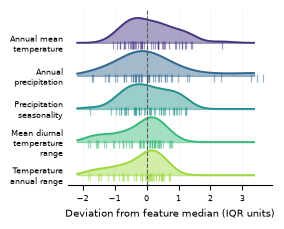

In [28]:
climate_features = [
    "Annual mean temperature",
    "Annual precipitation",
    "Precipitation seasonality",
    "Mean diurnal temperature range",
    "Temperature annual range",
]

fig, ax = distribution_ridges(
    env_long,
    climate_features,
    # title="Climate features",
    figsize=(2.83, 2.3),
    savepath=(Path.cwd().parent) / 'figures/00_climate_features_distribution.pdf'
)

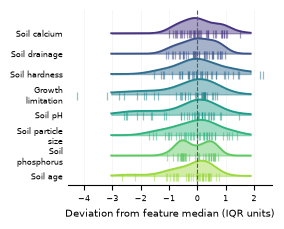

In [29]:
soil_features = env_long[env_long.domain.eq("Soil")].feature_label.unique().tolist()
soil_features.remove("Ecological soil class")  # Remove categorical feature

fig, ax = distribution_ridges(
    env_long,
    soil_features,
    # title="Soil features",
    figsize=(2.83, 2.3),
    savepath=(Path.cwd().parent) / 'figures/00_soil_features_distribution.pdf'
)

(<Figure size 566x500 with 1 Axes>,
 <Axes: xlabel='Deviation from feature median (IQR units)'>)

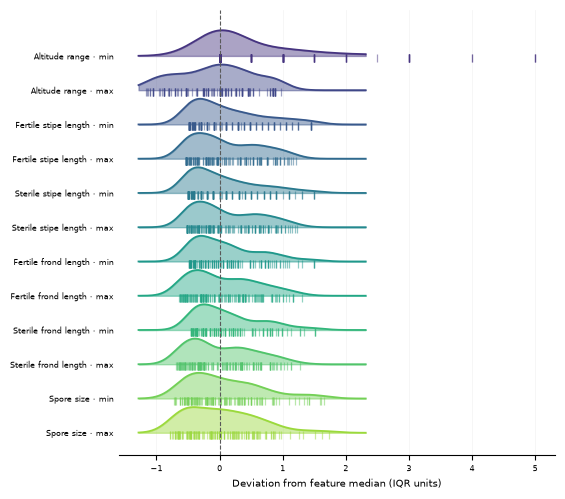

In [17]:
traits = [
    'AltMin', 'AltMax', 
    'FerstipeMin', 'FerstipeMax', 
    'SterileStipeMin', 'SterileStipeMax', 
          'FertileFrondMin', 'FertileFrondMax', 
          'SterileFrondMin', 'SterileFrondMax', 
    'SporeMin', 'SporeMax', 
          ]

traits_renames = {
    'AltMin': "Altitude range · min",
    'AltMax': "Altitude range · max",
    'FertileFrondMin': "Fertile frond length · min",
    'FertileFrondMax': "Fertile frond length · max",
    'SterileFrondMin': "Sterile frond length · min",
    'SterileFrondMax': "Sterile frond length · max",
    'FerstipeMin': "Fertile stipe length · min",
    'FerstipeMax': "Fertile stipe length · max",
    'SterileStipeMin': "Sterile stipe length · min",
    'SterileStipeMax': "Sterile stipe length · max",
    'SporeMin': "Spore size · min",
    'SporeMax': "Spore size · max",
}
traits_melted = trait_minmax.reset_index().melt(id_vars="Species", value_vars=traits, var_name="feature_label", value_name="value")
distribution_ridges(
    traits_melted,
    traits_melted.feature_label.unique().tolist(),
    # title="Trait distributions",
    featuredict=traits_renames,
    flier_quantiles=(0.05, 0.90),
    figsize=(5.66, 5),
    savepath=(Path.cwd().parent) / 'figures/00_trait_distributions.pdf'
)

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

def ridgeline(df, pattern, xlabel, *, cmap="viridis", bandwidth=None, figsize=(7, 5.5),
              savepath=None):
    d = df[df.feature_label.str.contains(pattern, case=False, na=False)].copy()
    d["month"] = d.feature_label.str.extract(r"·\s*(\w+)$")[0]
    d["month"] = pd.Categorical(d["month"], list(MONTHS.values()), ordered=True)

    x = np.linspace(d.value.min(), d.value.max(), 500)
    months = [m for m in MONTHS.values() if (d.month == m).any()]

    colors = plt.get_cmap(cmap)(np.linspace(0.15, 0.85, len(months)))

    fig, ax = plt.subplots(figsize=figsize)

    for i, (month, color) in enumerate(zip(months[::-1], colors[::-1])):
        values = d.loc[d.month == month, "value"].dropna().to_numpy()
        density = gaussian_kde(values, bw_method=bandwidth)(x)
        density /= density.max()

        ax.fill_between(x, i, i + 0.85 * density, color=color, alpha=.7)
        ax.plot(x, i + 0.85 * density, color=color, lw=1)
        ax.axhline(i, lw=.4, alpha=.25)

    ax.set(
        yticks=np.arange(len(months)),
        yticklabels=months[::-1],
        xlabel=xlabel,
        ylabel="",
    )
    ax.tick_params(axis="y", length=0)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.grid(axis="x", alpha=.15, lw=.5)
    ax.set_axisbelow(True)
    if savepath is not None:
        fig.savefig(savepath, bbox_inches="tight")

    fig.tight_layout()
    return fig, ax

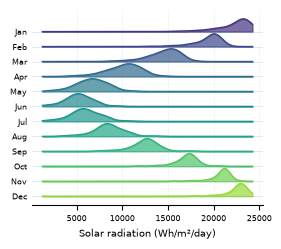

In [23]:
fig, ax = ridgeline(
    env_long,
    "Solar radiation",
    "Solar radiation (Wh/m²/day)",
    figsize=(2.83, 2.5),
    savepath=(Path.cwd().parent) / 'figures/00_solar_radiation_ridgeline.pdf'
)

(<Figure size 283x250 with 1 Axes>, <Axes: xlabel='Vapour pressure (kPa)'>)

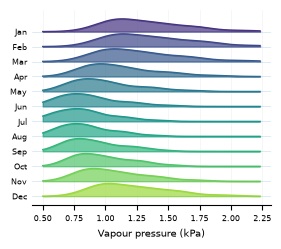

In [24]:
ridgeline(
    env_long,
    "Vapour pressure",
    "Vapour pressure (kPa)",
    figsize=(2.83, 2.5),
    savepath=(Path.cwd().parent) / 'figures/00_vapour_pressure_ridgeline.pdf'
)

## Species

In [15]:
dataset.get_species_graph()
dataset.species_graph

Computing transition probabilities:   0%|          | 0/374 [00:00<?, ?it/s]

Generating walks (CPU: 1): 100%|██████████| 200/200 [00:37<00:00,  5.27it/s]


Median distance: 697.767902



/home/smonaco/newzeland-plants/.venv/lib/python3.13/site-packages/torch_geometric/utils/convert.py:278: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  data_dict[key] = torch.as_tensor(value)


Data(x=[170, 16], edge_index=[2, 13288], weight=[13288], node_names=[170], traits_nanmask=[170, 6], traits_min=[170, 6], traits_max=[170, 6], traits_range=[170, 6], x_gen=[170, 10])

In [16]:
phylo_embedding = pd.DataFrame(
    dataset.species_graph.x.numpy(),
    index=dataset.species_graph.node_names,
)
phylo_embedding[phylo_embedding.eq(0).all(axis=1)] = np.nan
phylo_embedding

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
Anogramma_leptophylla,-1.437605,-0.469947,-0.309658,0.221211,2.607081,-0.159693,1.032787,-0.441336,0.897429,-0.333458,0.576955,-1.514554,-0.803055,0.656662,-0.291601,-0.575098
Pteris_macilenta,-0.814351,-0.486908,0.684676,-0.781178,3.026233,-0.679349,0.901302,-0.749528,1.027191,0.736233,-0.026359,-0.667420,-1.055343,0.443172,0.560143,-0.208050
Pteris_saxatilis,-1.027040,-0.542798,0.875055,-0.703561,3.075222,-0.688446,0.816846,-0.799424,1.000847,0.664053,-0.003922,-0.543647,-1.117684,0.598585,0.599017,-0.089640
Pteris_tremula,-1.115927,-0.513078,0.310283,-0.822397,3.219989,-0.743577,0.931591,-0.556001,1.119348,0.903230,-0.316691,-0.888817,-0.744361,0.420961,0.252690,-0.000955
Cheilanthes_distans,-0.989515,0.638487,-1.309386,-0.474342,2.416432,-0.016139,1.883610,-0.298476,-0.607266,-0.572964,-0.400761,-1.913643,-0.056211,-0.316071,-0.864238,-0.856387
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Psilotum_nudum,0.420148,0.320699,0.743912,0.826585,1.542925,1.845600,1.432121,-0.316620,-0.518524,-0.877404,1.139335,-1.191084,-0.139501,-0.927052,1.077274,-0.002014
Asplenium_appendiculatum,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Asplenium_flaccidum,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Davallia_tasmanii,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
from pathlib import Path

import matplotlib.pyplot as plt
from Bio import Phylo

tree_file = next(Path(dataset.root).glob("*.nwk"), None)
tree = Phylo.read(tree_file, "newick")

# Match the species used by the dataset.
species = set(getattr(dataset, dataset.pivot_feature).index)
tree_species = {leaf.name for leaf in tree.get_terminals()}
included = species & tree_species


In [18]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from Bio import Phylo
from matplotlib.collections import LineCollection
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse

# Okabe-Ito (colour-blind safe); repeated if more clades are requested.
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7",
           "#E69F00", "#56B4E9", "#7A5195", "#6B6B6B"]
BACKBONE = "#4d4d4d"
MISSING = "#e6e6e6"


# --------------------------------------------------------------------------- #
# Tree utilities
# --------------------------------------------------------------------------- #
def load_pruned_tree(tree_file, species):
    """Read a Newick file, keep only `species`, ladderize. Returns (tree, absent)."""
    tree = Phylo.read(tree_file, "newick")
    species = set(species)
    tree_species = {leaf.name for leaf in tree.get_terminals()}
    included = species & tree_species
    if len(included) < 2:
        raise ValueError("Fewer than two dataset species match the tree tip names.")
    for leaf in list(tree.get_terminals()):
        if leaf.name not in included:
            tree.prune(leaf)
    tree.ladderize()
    return tree, species - tree_species


def ensure_branch_lengths(tree):
    """Fall back to unit-length edges when lengths are incomplete."""
    branches = [c for c in tree.find_clades() if c is not tree.root]
    if any(c.branch_length is None for c in branches):
        for c in branches:
            c.branch_length = 1.0
        return "Topological distance (edges)"
    return "Phylogenetic branch length"


def node_depths(tree):
    depth = {tree.root: 0.0}
    for parent in tree.find_clades(order="preorder"):
        for ch in parent.clades:
            depth[ch] = depth[parent] + (ch.branch_length or 0.0)
    return depth


def split_major_clades(tree, k):
    """Greedily split the largest clade until k groups exist."""
    groups = [tree.root]
    while len(groups) < k:
        splittable = [g for g in groups if not g.is_terminal()]
        if not splittable:
            break
        g = max(splittable, key=lambda c: c.count_terminals())
        groups.remove(g)
        groups.extend(g.clades)
    return groups


def patristic_matrix(tree, tips, depth):
    """All tip-to-tip path lengths in O(n^2) via node depths."""
    n = len(tips)
    idx = {t: i for i, t in enumerate(tips)}
    tipidx = {}
    for c in tree.find_clades(order="postorder"):
        tipidx[c] = (np.array([idx[c]]) if c.is_terminal()
                     else np.concatenate([tipidx[ch] for ch in c.clades]))
    td = np.array([depth[t] for t in tips])
    D = np.zeros((n, n))
    for c in tree.get_nonterminals():
        for a in range(len(c.clades)):
            for b in range(a + 1, len(c.clades)):
                ia, ib = tipidx[c.clades[a]], tipidx[c.clades[b]]
                blk = td[ia][:, None] + td[ib][None, :] - 2 * depth[c]
                D[np.ix_(ia, ib)] = blk
                D[np.ix_(ib, ia)] = blk.T
    return D


# --------------------------------------------------------------------------- #
# Embedding utilities
# --------------------------------------------------------------------------- #
def pca_scores(X, k):
    Xc = X - X.mean(0)
    U, S, _ = np.linalg.svd(Xc, full_matrices=False)
    k = min(k, len(S))
    return U[:, :k] * S[:k], (S ** 2 / (S ** 2).sum())[:k]


def embedding_distance(X, metric="cosine"):
    if metric == "cosine":
        Xn = X / np.linalg.norm(X, axis=1, keepdims=True).clip(1e-12)
        D = 1.0 - Xn @ Xn.T
    elif metric == "euclidean":
        sq = (X ** 2).sum(1)
        D = np.sqrt((sq[:, None] + sq[None, :] - 2 * X @ X.T).clip(0))
    else:
        raise ValueError("metric must be 'cosine' or 'euclidean'")
    D = D.clip(0)
    np.fill_diagonal(D, 0.0)
    return D


def _rank(x):
    return pd.Series(x).rank().to_numpy()


def mantel_spearman(D1, D2, n_perm=999, rng=None):
    """Spearman rho between two distance matrices + one-sided permutation p."""
    rng = rng or np.random.default_rng(0)
    n = D1.shape[0]
    iu = np.triu_indices(n, 1)
    r1, r2 = _rank(D1[iu]), _rank(D2[iu])
    z1 = (r1 - r1.mean()) / r1.std()
    z2v = (r2 - r2.mean()) / r2.std()
    rho = float((z1 * z2v).mean())
    Z2 = np.zeros((n, n))
    Z2[iu] = z2v
    Z2 = Z2 + Z2.T
    hits = 0
    for _ in range(n_perm):
        p = rng.permutation(n)
        hits += (z1 * Z2[np.ix_(p, p)][iu]).mean() >= rho
    return rho, (1 + hits) / (n_perm + 1)


# --------------------------------------------------------------------------- #
# Drawing helpers
# --------------------------------------------------------------------------- #
def _nice_step(x):
    e = 10 ** np.floor(np.log10(x))
    return min((m * e for m in (1, 2, 5, 10) if m * e >= x), default=x)


def _axes_radius_pts(fig, ax):
    pos = ax.get_position()
    w, h = fig.get_size_inches()
    return 0.5 * min(w * pos.width, h * pos.height) * 72


def _to_unit(v, lo=2, hi=98):
    a, b = np.nanpercentile(v, [lo, hi])
    return np.clip((v - a) / (b - a + 1e-12), 0, 1)


def _arc(r, t0, t1, step=0.01):
    tt = np.linspace(t0, t1, max(2, int(np.ceil((t1 - t0) / step))) + 1)
    return list(zip(tt, np.full_like(tt, r)))


# --------------------------------------------------------------------------- #
# Main figure
# --------------------------------------------------------------------------- #
def plot_phylo_figure(
    tree,
    embeddings: pd.DataFrame | None = None,
    trait: pd.Series | None = None,
    *,
    n_clades=6,
    clade_names: dict | None = None,
    trait_label="Trait",
    distance_label="Phylogenetic branch length",
    title=None,
    cmap="viridis",
    n_pcs=2,
    dist_metric="cosine",
    n_perm=999,
    gap_deg=14.0,
    label_tips=True,
    figsize=None,
    seed=0,
    plot_bc=False,
):
    """
    embeddings : DataFrame (species x dims), index = tip names. Missing species are greyed.
    trait      : Series indexed by tip name (scalar per species) -> outer bar ring.
    """
    rng = np.random.default_rng(seed)
    clade_names = clade_names or {}
    n_pcs = max(2, n_pcs)

    tips = tree.get_terminals()
    n = len(tips)
    names = [t.name for t in tips]
    depth = node_depths(tree)
    R = max(depth[t] for t in tips)

    # ---- clades --------------------------------------------------------- #
    tip_pos = {t: i for i, t in enumerate(tips)}
    groups = split_major_clades(tree, n_clades)
    groups.sort(key=lambda g: min(tip_pos[t] for t in g.get_terminals()))
    colours = ['black'] * len(groups)
    # colours = (PALETTE * (len(groups) // len(PALETTE) + 1))[:len(groups)]
    clade_of = {c: gi for gi, g in enumerate(groups) for c in g.find_clades()}
    tip_group = np.array([clade_of[t] for t in tips])

    # ---- data ----------------------------------------------------------- #
    has_emb = embeddings is not None
    if has_emb:
        X = embeddings.reindex(names).to_numpy(float)
        valid = ~np.isnan(X).any(1)
        if valid.sum() < 3:
            raise ValueError("Fewer than three species have embeddings.")
        scores = np.full((n, n_pcs), np.nan)
        sc, var = pca_scores(X[valid], n_pcs)
        scores[valid, :sc.shape[1]] = sc
    tvals = None
    if trait is not None:
        tvals = trait.reindex(names).to_numpy(float)

    # ---- figure / axes ---------------------------------------------------#
    if has_emb:
        fig = plt.figure(figsize=figsize or (13.5, 7.6))
        gs = GridSpec(2, 2, figure=fig, width_ratios=[1.45, 1], hspace=0.34,
                      wspace=0.12, left=0.02, right=0.975, top=0.955, bottom=0.07)
        ax = fig.add_subplot(gs[:, 0], projection="polar")
    else:
        fig = plt.figure(figsize=figsize or (8.6, 8.6))
        ax = fig.add_subplot(111, projection="polar")
        fig.subplots_adjust(left=0.03, right=0.97, top=0.95, bottom=0.06)

    # ---- radial geometry -------------------------------------------------#
    gap = np.deg2rad(gap_deg)
    theta_tips = np.linspace(gap / 2, 2 * np.pi - gap / 2, n)
    dth = (theta_tips[1] - theta_tips[0]) if n > 1 else 0.1
    theta = {t: theta_tips[i] for i, t in enumerate(tips)}
    for node in tree.find_clades(order="postorder"):
        if not node.is_terminal():
            a = [theta[c] for c in node.clades]
            theta[node] = 0.5 * (min(a) + max(a))

    # rings = [("clade", 0.035 * R)]
    rings = []
    if has_emb:
        rings += [(f"PC{k + 1}", 0.055 * R) for k in range(n_pcs)]
    if tvals is not None:
        rings += [(trait_label, 0.10 * R)]
    ring_gap = 0.012 * R
    r_cursor = R * 1.02
    ring_r0 = []
    for _, w in rings:
        ring_r0.append(r_cursor)
        r_cursor += w + ring_gap
    r_lab = r_cursor + 0.01 * R

    P = _axes_radius_pts(fig, ax)
    fs = 6.0
    rmax = r_lab * 1.03
    if label_tips:
        for _ in range(3):
            L = max(len(s) for s in names) * 0.52 * fs
            rmax = r_lab / (1 - min(1.06 * L / P, 0.5))
            circ = 2 * np.pi * P * (r_lab / rmax) * (1 - gap_deg / 360)
            fs = float(np.clip(0.85 * circ / n, 3.0, 8.0))

    # ---- tree branches ---------------------------------------------------#
    lw = float(np.clip(60 / n, 0.35, 1.2))
    segs, cols = [], []
    for node in tree.find_clades(order="preorder"):
        if node.is_terminal():
            continue
        r_n = depth[node]
        th = [theta[c] for c in node.clades]
        if r_n > 0 and len(th) > 1:
            segs.append(_arc(r_n, min(th), max(th)))
            cols.append(colours[clade_of[node]] if node in clade_of else BACKBONE)
        for ch in node.clades:
            segs.append([(theta[ch], r_n), (theta[ch], depth[ch])])
            cols.append(colours[clade_of[ch]] if ch in clade_of else BACKBONE)
    lc = LineCollection(segs, colors=cols, linewidths=lw, zorder=3)
    lc.set_capstyle("round")
    ax.add_collection(lc, autolim=False)

    # guides from tip to ring start + distance grid
    guides = [[(theta[t], depth[t]), (theta[t], R * 1.015)]
              for t in tips if depth[t] < R * 0.995]
    if guides:
        ax.add_collection(LineCollection(guides, colors="#b5b5b5", linewidths=0.3,
                                         linestyles=(0, (1, 2)), zorder=1),
                          autolim=False)
    step = _nice_step(R / 3)
    for tk in np.arange(step, R * 0.999, step):
        ax.add_collection(LineCollection([_arc(tk, theta_tips[0], theta_tips[-1])],
                                         colors="#dcdcdc", linewidths=0.4, zorder=0),
                          autolim=False)
        ax.text(0, tk, f"{tk:g}", rotation=90, ha="center", va="center",
                fontsize=5.5, color="#8a8a8a")

    # ---- rings -----------------------------------------------------------#
    cm = mpl.colormaps[cmap]
    grp_cols = [colours[g] for g in tip_group]
    for (name, w), r0 in zip(rings, ring_r0):
        if name == "clade":
            c = grp_cols
            ax.bar(theta_tips, w, width=dth, bottom=r0, color=c, edgecolor=c,
                   linewidth=0.3, zorder=2)
        elif name.startswith("PC"):
            k = int(name[2:]) - 1
            u = _to_unit(scores[:, k])
            c = [MISSING if np.isnan(x) else cm(x) for x in u]
            ax.bar(theta_tips, w, width=dth, bottom=r0, color=c, edgecolor=c,
                   linewidth=0.3, zorder=2)
        else:  # trait bars
            u = np.nan_to_num(_to_unit(tvals, 0, 100), nan=0.0)
            ax.add_collection(LineCollection([_arc(r0, theta_tips[0], theta_tips[-1])],
                                             colors="#9a9a9a", linewidths=0.4, zorder=2),
                              autolim=False)
            ax.bar(theta_tips, w * (0.04 + 0.96 * u), width=dth * 0.82, bottom=r0,
                   color=grp_cols, edgecolor="none", alpha=0.9, zorder=2)
        ax.text(0, r0 + w / 2, name, rotation=90, ha="center", va="center",
                fontsize=6, color="#333333")

    # ---- tip labels ------------------------------------------------------#
    if label_tips:
        for t, th in zip(tips, theta_tips):
            deg = np.degrees(th)
            flip = 90 < deg < 270
            ax.text(th, r_lab, t.name.replace("_", " "),
                    rotation=deg + 180 if flip else deg, rotation_mode="anchor",
                    ha="right" if flip else "left", va="center",
                    fontsize=fs, fontstyle="italic", color="#222222")

    ax.set_ylim(0, rmax)
    ax.set_axis_off()

    # ---- legend / colourbar / caption -------------------------------------#
    handles = [Line2D([], [], marker="s", ls="", ms=6, color=colours[gi],
                      label=f"{clade_names.get(gi, f'Clade {gi + 1}')} "
                            f"(n={(tip_group == gi).sum()})")
               for gi in range(len(groups))]
    # leg = ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(-0.02, -0.01),
    #                 frameon=False, fontsize=7, title="Major clades", title_fontsize=7.5,
    #                 handletextpad=0.3, labelspacing=0.3)
    # leg._legend_box.align = "left"
    if has_emb:
        cax = ax.inset_axes((0.72, 0.03, 0.22, 0.02))
        cb = fig.colorbar(mpl.cm.ScalarMappable(mpl.colors.Normalize(0, 1), cm),
                          cax=cax, orientation="horizontal")
        cb.set_ticks([0, 1])
        cb.set_ticklabels(["low", "high"], fontsize=7)
        cb.outline.set_linewidth(0.3)
        cax.tick_params(length=2, width=0.3, pad=1)
        cax.set_title("Embedding PC score", fontsize=8, pad=2)
    # ax.text(0.5, -0.015, f"Grey rings: {distance_label.lower()}", transform=ax.transAxes,
    #         ha="center", va="top", fontsize=6.5, color="#666666")
    if plot_bc:
        ax.text(0.0, 1.0, "a", transform=ax.transAxes, fontsize=12, fontweight="bold",
                va="top")
    if title:
        ax.set_title(title, fontsize=10, pad=2, loc="center")

    info = {"n_tips": n, "groups": groups, "colours": colours}

    # ---- panels b / c ----------------------------------------------------#
    if has_emb and plot_bc:
        axB = fig.add_subplot(gs[0, 1])
        v = valid
        axB.scatter(scores[v, 0], scores[v, 1], c=[grp_cols[i] for i in np.flatnonzero(v)],
                    s=20, edgecolors="white", linewidths=0.4, zorder=3)
        for gi in range(len(groups)):
            m = v & (tip_group == gi)
            if m.sum() < 4:
                continue
            pts = scores[m, :2]
            w_, V = np.linalg.eigh(np.cov(pts.T))
            ang = np.degrees(np.arctan2(V[1, 1], V[0, 1]))
            axB.add_patch(Ellipse(pts.mean(0), 2 * 1.5 * np.sqrt(w_[1]),
                                  2 * 1.5 * np.sqrt(w_[0]), angle=ang,
                                  facecolor=colours[gi], alpha=0.12, edgecolor=colours[gi],
                                  linewidth=0.6, zorder=1))
        axB.set_xlabel(f"PC1 ({var[0] * 100:.1f}%)", fontsize=8)
        axB.set_ylabel(f"PC2 ({var[1] * 100:.1f}%)", fontsize=8)
        axB.set_title("Embedding space", fontsize=9, loc="left", pad=4)

        depth_t = depth
        Dphy = patristic_matrix(tree, tips, depth_t)[np.ix_(v, v)]
        Demb = embedding_distance(X[v], dist_metric)
        rho, pval = mantel_spearman(Dphy, Demb, n_perm, rng)
        iu = np.triu_indices(Dphy.shape[0], 1)
        x, y = Dphy[iu], Demb[iu]
        axC = fig.add_subplot(gs[1, 1])
        axC.hexbin(x, y, gridsize=38, cmap="Greys", bins="log", mincnt=1,
                   linewidths=0, zorder=1)
        # quantile bins; ties (e.g. ultrametric trees) can collapse bins, so drop empties
        edges = np.unique(np.quantile(x, np.linspace(0, 1, 13)))
        bi = np.clip(np.digitize(x, edges[1:-1]), 0, len(edges) - 2)
        keep = [b for b in range(len(edges) - 1) if (bi == b).any()]
        bx = np.array([x[bi == b].mean() for b in keep])
        q = np.array([np.percentile(y[bi == b], [25, 50, 75]) for b in keep])
        axC.fill_between(bx, q[:, 0], q[:, 2], color="#D55E00", alpha=0.2, lw=0, zorder=2)
        axC.plot(bx, q[:, 1], "-o", color="#D55E00", ms=3, lw=1.2, zorder=3)
        ptxt = f"{pval:.3f}" if pval >= 0.001 else "< 0.001"
        axC.text(0.04, 0.95, f"Spearman $\\rho$ = {rho:.2f}\nMantel $p$ {('= ' + ptxt) if pval >= 0.001 else ptxt}",
                 transform=axC.transAxes, va="top", fontsize=8)
        axC.set_xlabel("Patristic distance" + (" (branch length)" if "length" in distance_label
                                               else " (edges)"), fontsize=8)
        axC.set_ylabel(f"Embedding distance ({dist_metric})", fontsize=8)
        axC.set_title("Do embeddings track phylogeny?", fontsize=9, loc="left", pad=4)
        for a_, lab in ((axB, "b"), (axC, "c")):
            a_.spines[["top", "right"]].set_visible(False)
            a_.tick_params(labelsize=7, width=0.5, length=3)
            for s in a_.spines.values():
                s.set_linewidth(0.6)
            a_.text(-0.17, 1.12, lab, transform=a_.transAxes, fontsize=12,
                    fontweight="bold", va="top")
        info.update(rho=rho, mantel_p=pval, pca_var=var)
    return fig, info


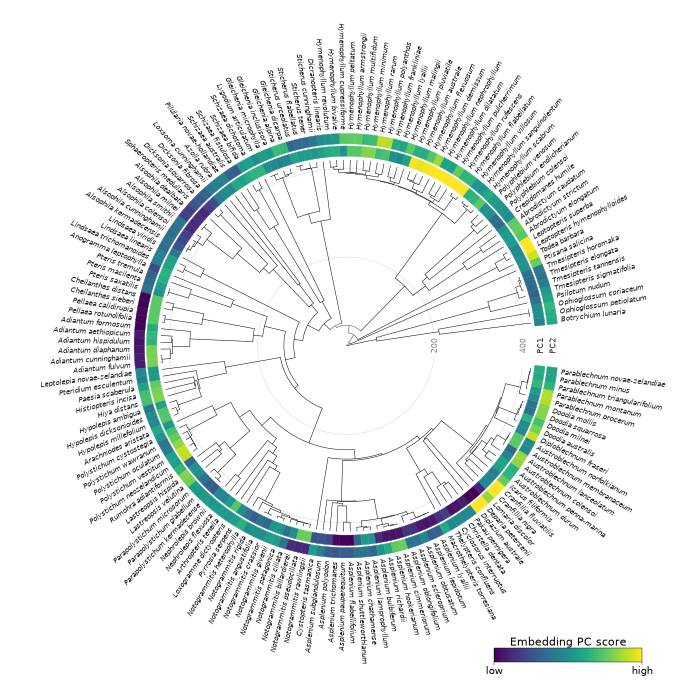

Dataset species absent from the Newick tree: 4


In [19]:
from pathlib import Path
import matplotlib.pyplot as plt
# from phylogeny_figure import load_pruned_tree, ensure_branch_lengths, plot_phylo_figure

plt.rcParams.update({"pdf.fonttype": 42, "font.family": "sans-serif"})  # editable text in the PDF

tree_file = next(Path(dataset.root).glob("*.nwk"), None)
if tree_file is None:
    raise FileNotFoundError(f"No Newick file found in {dataset.root}")

species = set(getattr(dataset, dataset.pivot_feature).index)
tree, absent = load_pruned_tree(tree_file, species)
distance_label = ensure_branch_lengths(tree)

# Optional: replace with your own objects, both indexed by species name.
embeddings = phylo_embedding   # e.g. pd.DataFrame(model_embeddings, index=species_index)
trait = None        # e.g. a pd.Series per species

fig, info = plot_phylo_figure(
    tree, embeddings, trait,
    n_clades=6,
    clade_names={0: "Hymenophyllales", 1: "Cyatheales"},  # optional, by clade index
    trait_label="Trait",
    distance_label=distance_label,
    # plot_bc=True,
)
fig.savefig(Path.cwd().parent / "figures/00_phylogeny_figure.pdf", bbox_inches="tight")
plt.show()
print(f"Dataset species absent from the Newick tree: {len(absent)}")



I would **not display 45 feature names around this heatmap**. The raw-distribution figure already identifies them. Domain separators can be added if you want this in the final paper.

---

# 6. Species distributions on a New Zealand map

The notebook creates per-species occurrence records by reading each distribution raster, retaining positive occurrence cells, assigning them to the nearest spatial cluster, and summing occurrence values within clusters. new_dataset

There are too many species to assign a useful color to every species in one map. I would select approximately **eight to twelve species spanning the observed range-size distribution**. That is better than choosing only the most widespread taxa because it shows both geographically restricted and broadly distributed species.

## Select representative species by spatial range


In [20]:
coverage = (
    occurrences
    .groupby("species")["cluster"]
    .nunique()
    .sort_values()
)

N_SPECIES = 10

# Equally spaced quantiles of observed range size
idx = np.linspace(
    0,
    len(coverage) - 1,
    N_SPECIES,
).round().astype(int)

species_to_show = (
    coverage.iloc[idx]
    .index
    .tolist()
)

species_to_show

['Arachniodes_aristata',
 'Asplenium_subglandulosum',
 'Polystichum_oculatum',
 'Notogrammitis_rigida',
 'Pteris_macilenta',
 'Loxogramme_dictyopteris',
 'Paesia_scaberula',
 'Polyphlebium_venosum',
 'Alsophila_smithii',
 'Hymenophyllum_multifidum']



If you have a biologically motivated list of case-study species, I would use that instead. It creates a direct link between this appendix figure and the later species-level attribution analysis.

## Overlay map

Because the occurrence rasters cross the longitude discontinuity near New Zealand, I would center the map close to the antimeridian. The notebook itself contains coordinates spanning approximately \(-179^\circ\) to \(180^\circ\), so a conventional Greenwich-centered map can split nearby locations visually. new_dataset


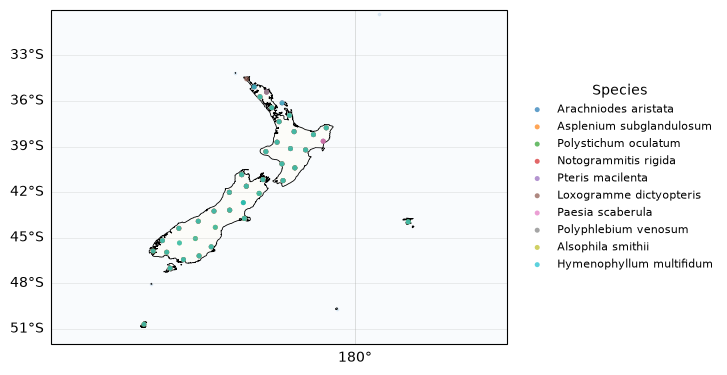

In [21]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

map_data = occurrences[
    occurrences["species"].isin(species_to_show)
].copy()

projection = ccrs.PlateCarree(
    central_longitude=180
)

data_crs = ccrs.PlateCarree()

fig = plt.figure(
    figsize=(7.4, 8.0)
)

ax = fig.add_subplot(
    111,
    projection=projection,
)

# New Zealand and surrounding islands
ax.set_extent(
    [160, 190, -52, -30],
    crs=data_crs,
)

ax.add_feature(
    cfeature.LAND,
    alpha=0.15,
)

ax.add_feature(
    cfeature.OCEAN,
    alpha=0.05,
)

ax.coastlines(
    resolution="10m",
    linewidth=0.6,
)

# All available spatial clusters as geographic context
ax.scatter(
    cluster_xy["lon"],
    cluster_xy["lat"],
    s=3,
    alpha=0.10,
    transform=data_crs,
    zorder=1,
)

palette = sns.color_palette(
    n_colors=len(species_to_show)
)

for color, species in zip(
    palette,
    species_to_show,
):
    d = map_data[
        map_data["species"].eq(species)
    ]

    ax.scatter(
        d["lon"],
        d["lat"],
        s=13,
        alpha=0.70,
        color=color,
        edgecolors="none",
        transform=data_crs,
        label=species.replace("_", " "),
        zorder=2,
    )

gridlines = ax.gridlines(
    draw_labels=True,
    linewidth=0.4,
    alpha=0.4,
)

gridlines.top_labels = False
gridlines.right_labels = False

ax.legend(
    title="Species",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=8,
)

plt.tight_layout()

plt.savefig(
    "appendix_species_distributions_map.pdf",
    bbox_inches="tight",
)

plt.show()

A suitable caption:

```latex
\caption{
Geographic occurrence distributions for representative fern species in the
dataset. Points show spatial clusters with recorded occurrences. Species were
selected at approximately equally spaced quantiles of the observed number of
occupied spatial clusters to represent both geographically restricted and
widespread taxa. Faint background points show the spatial clusters covered by
the environmental dataset.
}
```

## 6b. Alternative I prefer scientifically: small-multiple maps

The overlay is attractive, but overlapping occurrences make it difficult to distinguish species with similar geographic ranges. For an appendix, a faceted map is arguably stronger.

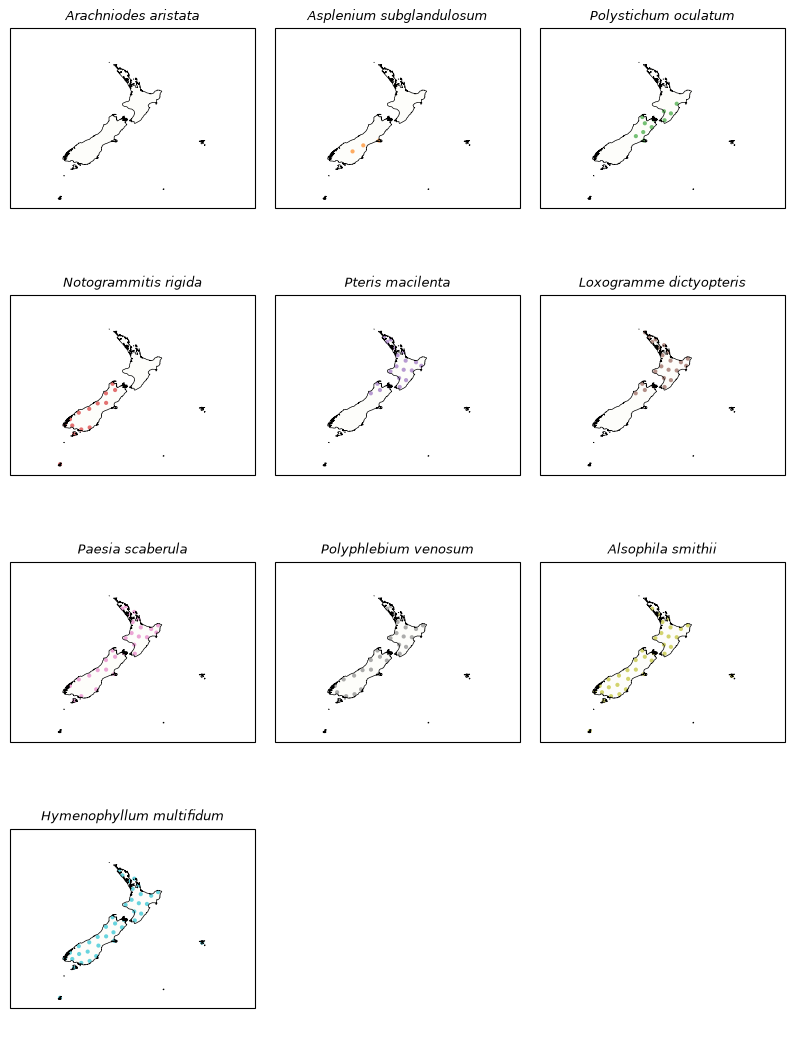

In [22]:
N_COLS = 3
N_ROWS = int(
    np.ceil(len(species_to_show) / N_COLS)
)

fig = plt.figure(
    figsize=(10, 3.4 * N_ROWS)
)

gs = fig.add_gridspec(
    N_ROWS,
    N_COLS,
    hspace=0.08,
    wspace=0.08,
)

palette = sns.color_palette(
    n_colors=len(species_to_show)
)

for i, (species, color) in enumerate(
    zip(species_to_show, palette)
):
    ax = fig.add_subplot(
        gs[i // N_COLS, i % N_COLS],
        projection=projection,
    )

    ax.set_extent(
        [160, 190, -52, -30],
        crs=data_crs,
    )

    ax.add_feature(
        cfeature.LAND,
        alpha=0.12,
    )

    ax.coastlines(
        resolution="10m",
        linewidth=0.5,
    )

    d = occurrences[
        occurrences["species"].eq(species)
    ]

    ax.scatter(
        d["lon"],
        d["lat"],
        s=9,
        alpha=0.65,
        color=color,
        edgecolors="none",
        transform=data_crs,
    )

    ax.set_title(
        species.replace("_", " "),
        fontsize=9,
        fontstyle="italic",
    )

# Hide unused grid cells
for j in range(
    len(species_to_show),
    N_ROWS * N_COLS,
):
    ax = fig.add_subplot(
        gs[j // N_COLS, j % N_COLS]
    )
    ax.axis("off")

plt.savefig(
    "appendix_species_distributions_facets.pdf",
    bbox_inches="tight",
)

plt.show()

For the paper, I would use the **faceted version if geographic range heterogeneity is itself a result**, and the colored overlay if the goal is simply to demonstrate dataset coverage.

---

## 7. A compact taxonomy panel is also worth considering

The notebook already inspects counts by genus and family from `Species list.xlsx`. new_dataset Since phylogenetic information is central to your model, I would not omit taxonomic composition entirely.

A single two-panel figure is enough:

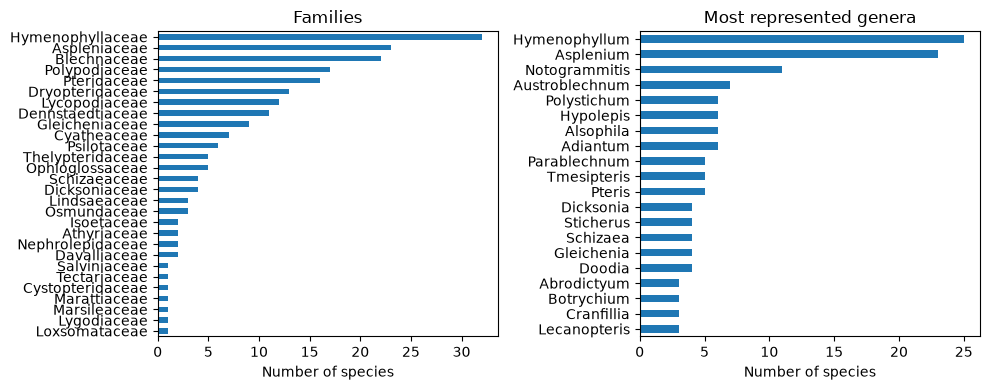

In [23]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4),
)

family_counts = (
    species_meta["Family"]
    .value_counts()
    .sort_values()
)

genus_counts = (
    species_meta["Genus"]
    .value_counts()
    .head(20)
    .sort_values()
)

family_counts.plot.barh(
    ax=axes[0]
)

genus_counts.plot.barh(
    ax=axes[1]
)

axes[0].set_xlabel("Number of species")
axes[0].set_ylabel("")
axes[0].set_title("Families")

axes[1].set_xlabel("Number of species")
axes[1].set_ylabel("")
axes[1].set_title("Most represented genera")

plt.tight_layout()

plt.savefig(
    "appendix_taxonomic_composition.pdf",
    bbox_inches="tight",
)

plt.show()

### What I would actually put in the appendix

I would order the appendix as:

**A.1 Trait coverage and distributions**  
One composite figure with missingness plus all 12 target distributions.

**A.2 Environmental covariates**  
All raw feature distributions split across climate and soil/environment pages. Follow this with the correlation matrix if appendix length permits.

**A.3 Taxonomic and spatial coverage**  
One compact family/genus panel, followed by the species-distribution map.

I would avoid dozens of individual figures. The important role of this appendix is to make three dataset properties immediately visible: **which prediction targets are sparse or skewed, how the environmental input space is distributed and correlated, and how heterogeneous the species' geographic coverage is**. This also gives useful context for the later reconstruction and attribution analyses without repeating their results.